In [49]:
import pandas as pd 
import numpy as np 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay, 
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import export_graphviz
from IPython.display import Image
import graphviz
from sklearn.preprocessing import MinMaxScaler


We want to see what the data looks like

In [19]:
df = pd.read_csv('telecom_churn.csv')
df.head(5)

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


In [20]:
df.isna().sum()

Churn              0
AccountWeeks       0
ContractRenewal    0
DataPlan           0
DataUsage          0
CustServCalls      0
DayMins            0
DayCalls           0
MonthlyCharge      0
OverageFee         0
RoamMins           0
dtype: int64

In [21]:
df.describe()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,0.144914,101.064806,0.903090,0.276628,0.816475,1.562856,179.775098,100.435644,56.305161,10.051488,10.237294
std,0.352067,39.822106,0.295879,0.447398,1.272668,1.315491,54.467389,20.069084,16.426032,2.535712,2.791840
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,0.000000,0.000000
25%,0.000000,74.000000,1.000000,0.000000,0.000000,1.000000,143.700000,87.000000,45.000000,8.330000,8.500000
50%,0.000000,101.000000,1.000000,0.000000,0.000000,1.000000,179.400000,101.000000,53.500000,10.070000,10.300000
75%,0.000000,127.000000,1.000000,1.000000,1.780000,2.000000,216.400000,114.000000,66.200000,11.770000,12.100000
max,1.000000,243.000000,1.000000,1.000000,5.400000,9.000000,350.800000,165.000000,111.300000,18.190000,20.000000


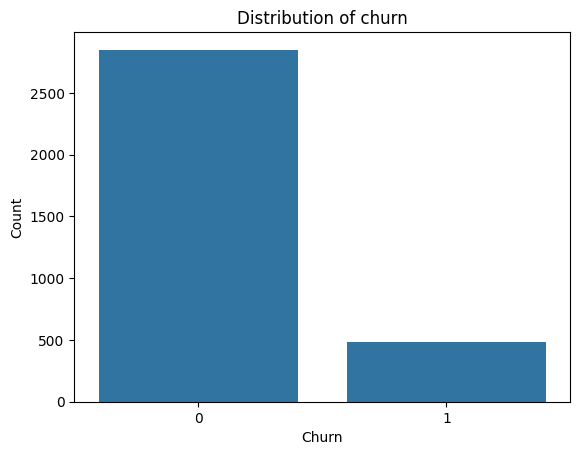

In [39]:
sns.countplot(x='Churn', data=df)

plt.title('Distribution of churn')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.show()

In [43]:
pct = df['Churn'].value_counts(normalize = True) * 100
print(pct)

Churn
0    85.508551
1    14.491449
Name: proportion, dtype: float64


Check any linear correlation between variables. We'll focus specifically on the Churn variable

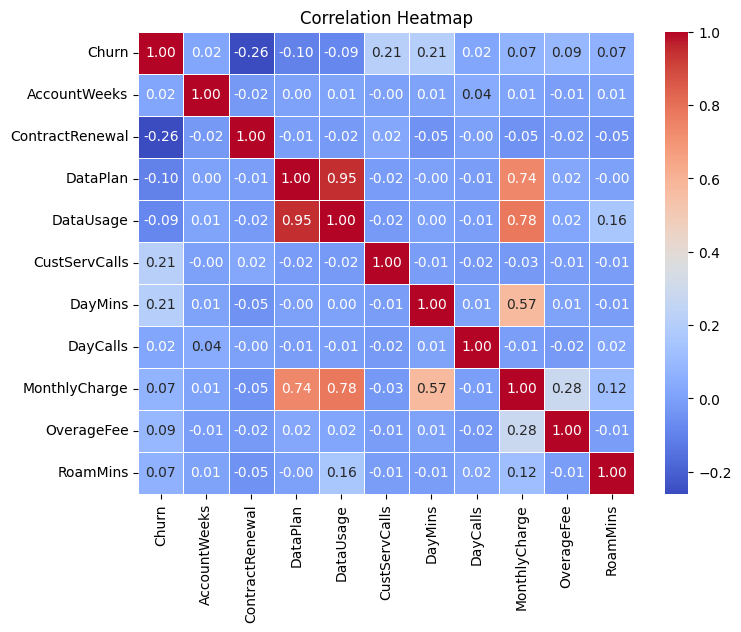

In [22]:
matrix = df.corr()
plt.figure(figsize=(8,6))
sns.heatmap(matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

We notice that correlations are not that high

# Radar Chart

In [50]:
features = [
    'AccountWeeks',
    'ContractRenewal',
    'DataPlan',
    'DataUsage',
    'CustServCalls',
    'OverageFee'
]

scaler = MinMaxScaler()
df_scaled = df.copy()
df_scaled[features] = scaler.fit_transform(df[features]) * 100

radar_data = df_scaled.groupby('Churn')[features].mean()

print(radar_data)

       AccountWeeks  ContractRenewal   DataPlan  DataUsage  CustServCalls  \
Churn                                                                       
0         41.237060        93.473684  29.543860  15.965757      16.109162   
1         42.010164        71.635611  16.563147  10.128824      24.775707   

       OverageFee  
Churn              
0       54.725770  
1       58.400687  


In [51]:
categories = [
    'Account Weeks',
    'Contract Renewal',
    'Data Plan',
    'Data Usage', 
    'Customer Service Calls',
    'Overage Fee'
]

In [52]:
N = len(categories)

In [53]:
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

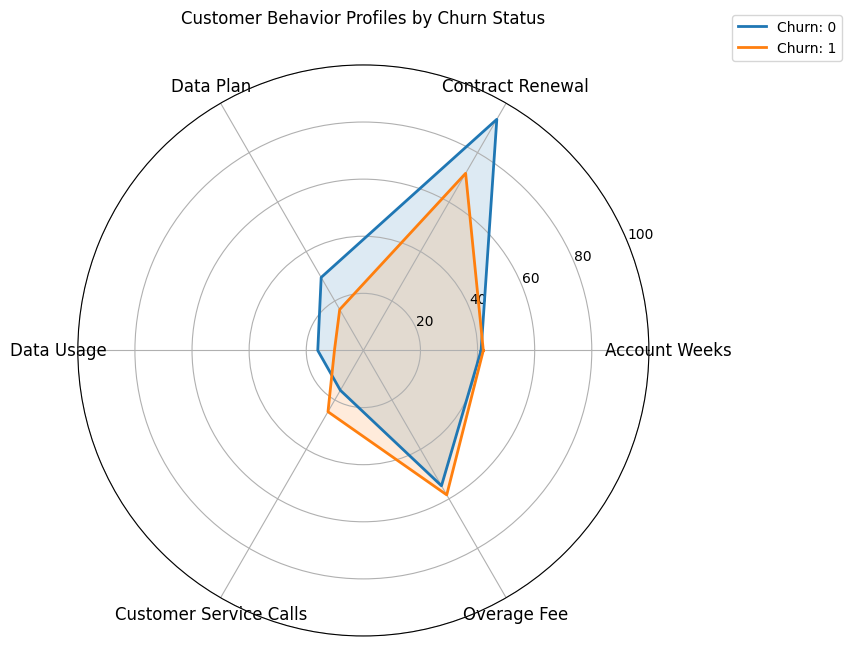

In [62]:
fig, ax = plt.subplots(
    figsize = (9,9),
    subplot_kw={'polar':True}
)

for churn_status in radar_data.index:
    values = radar_data.loc[churn_status].to_list()
    values += values[:1]
    
    ax.plot(
        angles,
        values,
        linewidth=2,
        label=f'Churn: {churn_status}'
    )
    
    ax.fill(angles, values, alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12)

ax.set_ylim(0, 100)
ax.set_title(
    'Customer Behavior Profiles by Churn Status',
    pad=30
)


ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
plt.tight_layout()
plt.show()


# Logistic Regression

In [23]:
x = df.drop(columns=['Churn'])
y = df.loc[:, 'Churn']

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    x,y, test_size = 0.20, random_state = 42
)

In [29]:
model = LogisticRegression(max_iter=1000
)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [30]:
y_pred = model.predict(X_test)

In [31]:
cm  = confusion_matrix(y_test, y_pred)
print("Matriz de confusión:")
print(cm)

Matriz de confusión:
[[556  10]
 [ 83  18]]


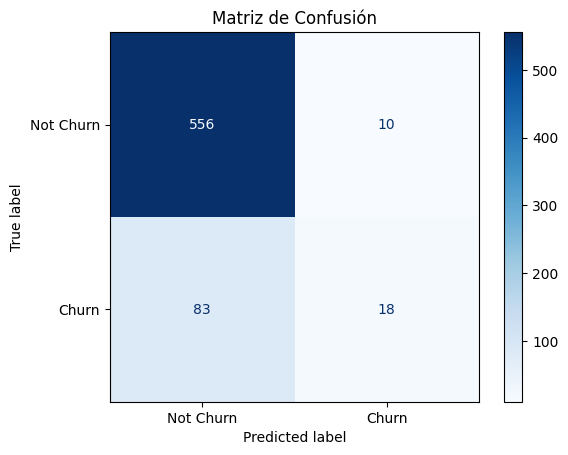

In [32]:
disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels=["Not Churn", "Churn"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusión")
plt.show()

In [36]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.8605697151424287
Precision: 0.6428571428571429
Recall: 0.1782178217821782
F1 Score: 0.27906976744186046


# Random Forest

In [64]:
rf = RandomForestClassifier()
rf.fit(X_train, y_train)

RandomForestClassifier()

In [65]:
y_pred_rf = rf.predict(X_test)

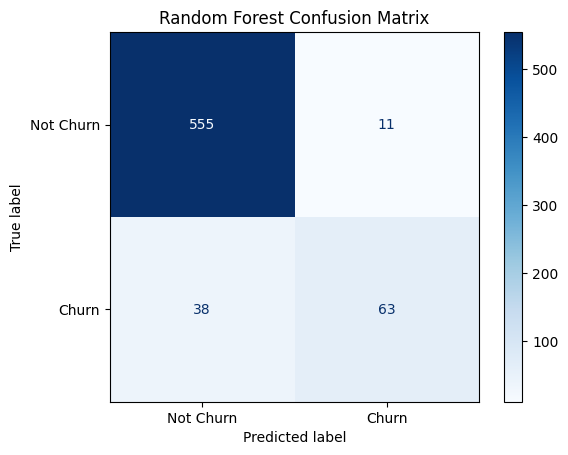

In [68]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=["Not Churn", "Churn"])
disp_rf.plot(cmap=plt.cm.Blues)
plt.title("Random Forest Confusion Matrix")
plt.show()